# Signals FBG

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import xarray as xr
from tqdm import tqdm
import glob
from scipy import signal
from scipy.integrate import cumulative_trapezoid
from numpy.lib.stride_tricks import sliding_window_view
from obspy.signal.filter import highpass, bandpass, lowpass
from obspy.signal.invsim import cosine_taper
from scipy.signal import spectrogram, detrend
from obspy.signal.trigger import classic_sta_lta, plot_trigger,trigger_onset
import obspy
import os
from itertools import combinations

In [2]:
data_dir = '../../data/gridsearch'
if not os.path.exists(data_dir):
    os.makedirs(data_dir)

In [3]:
plot_dir = '../../plots/recurrent_events'
if not os.path.exists(plot_dir):
    os.makedirs(plot_dir)

## Processing

### Importing the data

In [4]:
ncfiles = glob.glob('/mnt/ICELAND_2024/GUNNUVHER/FBG/LowFreqSampling/aligned_nc_converted/FBG_*nc')#+glob.glob('/mnt/ICELAND_2024/GUNNUVHER/FBG/LowFreqSampling/aligned_nc_converted/FBG_2025.02*nc')
ncfiles.sort()
for i, file in enumerate(tqdm(ncfiles)) : 
    ds = xr.open_dataset(file)
    ds = ds.drop_vars(['relative_Time', 'Temperature_calibration','Strain_calibration'])
    ds = ds.sel(Channel=2)
    if i == 0 :
        dsch_hstrain = ds.copy()
        continue
    dsch_hstrain = xr.concat([dsch_hstrain, ds], dim='Time')

100%|██████████| 347/347 [01:22<00:00,  4.22it/s]


### Cleaning the data

In [5]:
rng = np.arange(dsch_hstrain.Time.values[0], dsch_hstrain.Time.values[-1], 2, dtype='datetime64[s]')
dsch_hstrain = dsch_hstrain.sortby('Time')
dsch_hstrain = dsch_hstrain.drop_duplicates('Time')
dsch_hstrain = dsch_hstrain.reindex({'Time': rng}, method='nearest', tolerance=np.timedelta64(2, 's'))

/tmp/ipykernel_438033/2068137241.py:4: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  dsch_hstrain = dsch_hstrain.reindex({'Time': rng}, method='nearest', tolerance=np.timedelta64(2, 's'))


In [6]:
svv = dsch_hstrain.sel(FBG=3)

In [7]:
np.diff(svv.Time.values.astype('datetime64[s]')).mean()

numpy.timedelta64(2,'s')

### Detrend + filtering

In [8]:
def _detrend_ufunc(x) :
    med = np.nanmedian(x)#, axis=1).reshape(-1,1)
    dtrend = x - med
    dtrend = np.where(dtrend > 1, np.nan, dtrend)
    return dtrend

def detrend_signal(x) :
    return xr.apply_ufunc(_detrend_ufunc, x)

In [9]:
dtrend = detrend_signal(svv)

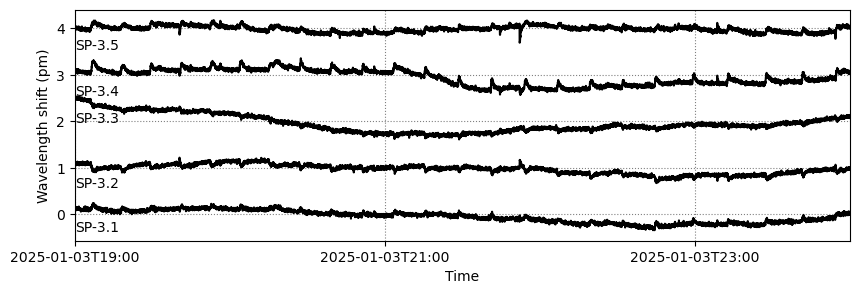

In [10]:
bgdate, endate = '2025-01-03T19', '2025-01-04T00'
plt.figure(figsize=(10,3))
for i in range(5):
    svv = dsch_hstrain.sel(FBG=i, Time=slice(bgdate, endate))
    dtrend_ = detrend(svv.Wavelength_nm.values*1000)
    plt.plot(svv.Time, dtrend_ + i*1, c='k')
    plt.text(np.datetime64(bgdate), (dtrend_[0] + i*1) - .5, 'SP-3.%i' %(i+1), c='k', fontsize=10)
plt.grid(ls=':', c='grey')
plt.ylabel('Wavelength shift (pm)')
plt.xlim(np.datetime64(bgdate), np.datetime64(endate))
plt.xlabel('Time')
plt.xticks(np.arange(np.datetime64(bgdate), np.datetime64(endate), np.timedelta64(2, 'h')),
           np.arange(np.datetime64(bgdate), np.datetime64(endate), np.timedelta64(2, 'h')).astype('datetime64[m]').astype(str))
plt.savefig(plot_dir+'/wavelength_shift_5FBGs_15min.png', bbox_inches='tight')
plt.show()



## Take a look to 15-minutes signal in Janurary

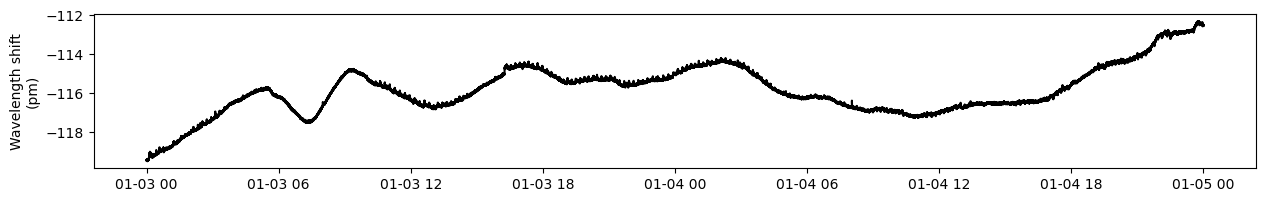

In [11]:
bgdate, endate = '2025-01-03T00', '2025-01-04T23'
%matplotlib inline
plt.figure(figsize=(15,2))
plt.plot(dtrend.sel(Time=slice(bgdate, endate)).Time, dtrend.sel(Time=slice(bgdate, endate)).Wavelength_nm.values*1000, color='k')
plt.ylabel('Wavelength shift\n(pm)')
plt.show()

In [12]:
st = obspy.Stream()
tr = obspy.Trace()
tr.stats.sampling_rate = 0.5
tr.stats.startdate = obspy.UTCDateTime(str(dtrend.sel(Time=slice(bgdate, endate)).Time.values[0]))
tr.data = dtrend.Wavelength_nm.sel(Time=slice(bgdate, endate)).values*1000
st.append(tr)

1 Trace(s) in Stream:
... | 1970-01-01T00:00:00.000000Z - 1970-01-02T23:59:58.000000Z | 0.5 Hz, 86400 samples

In [13]:
stc = st.copy()
stc.filter("highpass", freq=0.005, corners=4, zerophase=True)
stc.taper(max_percentage=.5, type='hann')


1 Trace(s) in Stream:
... | 1970-01-01T00:00:00.000000Z - 1970-01-02T23:59:58.000000Z | 0.5 Hz, 86400 samples

In [14]:
sta_lta = classic_sta_lta(stc[0].data, nsta=5, nlta=300)

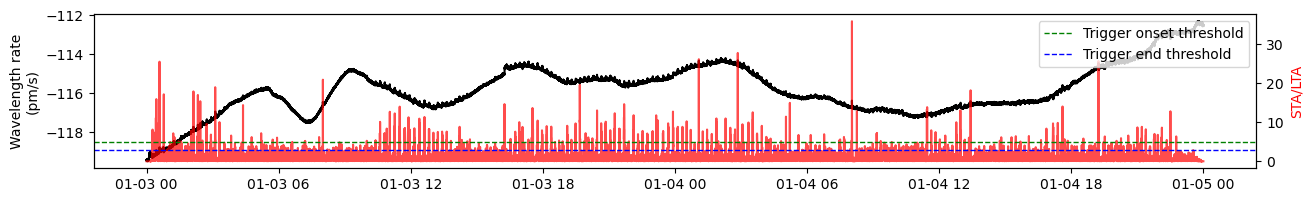

In [15]:
%matplotlib inline
fig, ax = plt.subplots(figsize=(15,2))
ax.plot(dtrend.sel(Time=slice(bgdate, endate)).Time, dtrend.Wavelength_nm.sel(Time=slice(bgdate, endate)).values*1000, color='k')
axb=ax.twinx()
axb.plot(dtrend.sel(Time=slice(bgdate, endate)).Time, sta_lta, color='r', alpha=0.7)
axb.axhline(5, color='g', linestyle='--', lw=1, label='Trigger onset threshold')
axb.axhline(3, color='b', linestyle='--', lw=1, label='Trigger end threshold')
axb.set_ylabel('STA/LTA', color='r')
ax.set_ylabel('Wavelength rate\n(pm/s)')
plt.legend()
plt.show()

In [16]:
triggers_sta_lta = trigger_onset(sta_lta, 3, 5)

In [17]:
events = []
max_amp_events = []
for trigger in triggers_sta_lta :
    event = st[0].data[trigger[0]-100:trigger[0]+200]
    events.append(event - np.nanmedian(event))
    max_amp_events.append(np.argmax(event) + trigger[0]-100)

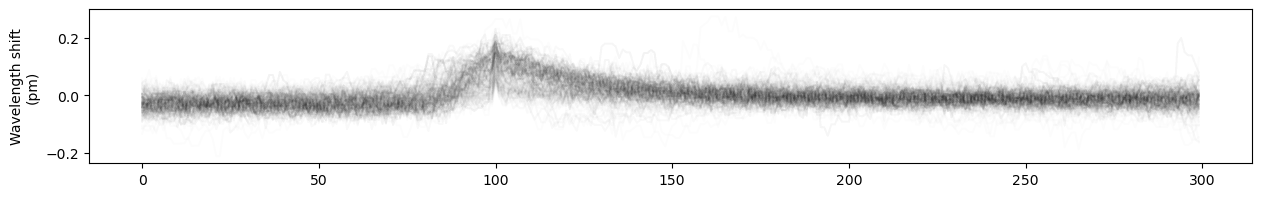

In [18]:
plt.figure(figsize=(15,2))
max_aligned_events = []
for i, max_loc_amp in enumerate(max_amp_events) :
    aligned_event = detrend(st[0].data[max_loc_amp-100:max_loc_amp+200])
    max_aligned_events.append(aligned_event)
    plt.plot(aligned_event, color='k', alpha=0.01)
plt.ylabel('Wavelength shift\n(pm)')
plt.show()

### Save all the events

In [19]:
np.save(data_dir+'/aligned_events_15min_FBG_3.npy', max_aligned_events)

### Plot median and average event

Text(0, 0.5, 'Wavelength shift\n(pm)')

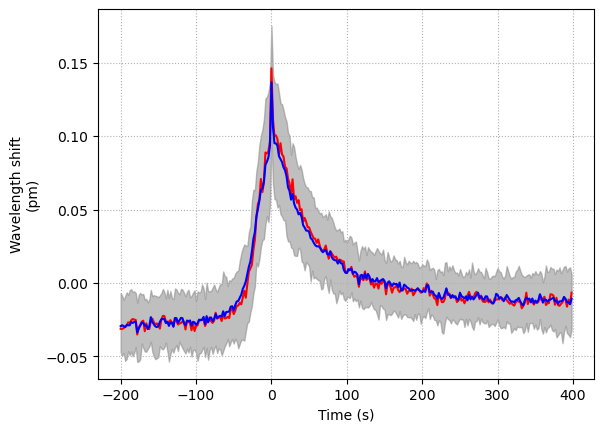

In [20]:
dt = np.diff(st[0].times()).mean()
plt.figure()
plt.plot(np.arange(-100, 200)*dt,np.median(max_aligned_events, axis=0), color='r')
plt.plot(np.arange(-100, 200)*dt,np.mean(max_aligned_events, axis=0), color='b')
plt.fill_between(np.arange(-100, 200)*dt, np.percentile(max_aligned_events, 25, axis=0), np.percentile(max_aligned_events, 75, axis=0), color='gray', alpha=0.5)
plt.grid(ls=':')
plt.xlabel('Time (s)')
plt.ylabel('Wavelength shift\n(pm)')

### Plot all the events

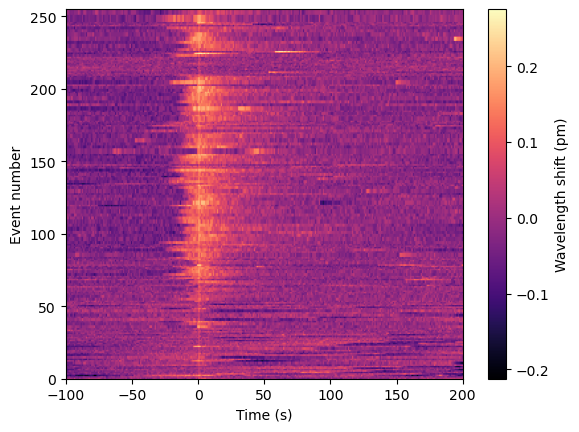

In [21]:
plt.figure()
plt.imshow(max_aligned_events, aspect='auto', cmap='magma', extent=[-100, 200, 0, len(max_aligned_events)])
plt.colorbar(label='Wavelength shift (pm)')
plt.xlabel('Time (s)')
plt.ylabel('Event number')
plt.show()

## Broadband CMG-3ESPCD Güralp seismometer

In [4]:
path = '/mnt/ICELAND_2024/GUNNUVHER/Seismic/Broadband/data/2025/202508/20250807/*z6*.gcf'

In [5]:
files = glob.glob(path, recursive=True)

In [6]:
files

['/mnt/ICELAND_2024/GUNNUVHER/Seismic/Broadband/data/2025/202508/20250807/o10z0_4893z6_20250807_0000.gcf',
 '/mnt/ICELAND_2024/GUNNUVHER/Seismic/Broadband/data/2025/202508/20250807/o10z0_4893z6_20250807_0100.gcf',
 '/mnt/ICELAND_2024/GUNNUVHER/Seismic/Broadband/data/2025/202508/20250807/o10z0_4893z6_20250807_0200.gcf',
 '/mnt/ICELAND_2024/GUNNUVHER/Seismic/Broadband/data/2025/202508/20250807/o10z0_4893z6_20250807_0300.gcf',
 '/mnt/ICELAND_2024/GUNNUVHER/Seismic/Broadband/data/2025/202508/20250807/o10z0_4893z6_20250807_0400.gcf',
 '/mnt/ICELAND_2024/GUNNUVHER/Seismic/Broadband/data/2025/202508/20250807/o10z0_4893z6_20250807_0500.gcf',
 '/mnt/ICELAND_2024/GUNNUVHER/Seismic/Broadband/data/2025/202508/20250807/o10z0_4893z6_20250807_0600.gcf',
 '/mnt/ICELAND_2024/GUNNUVHER/Seismic/Broadband/data/2025/202508/20250807/o10z0_4893z6_20250807_0700.gcf',
 '/mnt/ICELAND_2024/GUNNUVHER/Seismic/Broadband/data/2025/202508/20250807/o10z0_4893z6_20250807_0800.gcf',
 '/mnt/ICELAND_2024/GUNNUVHER/Seismic

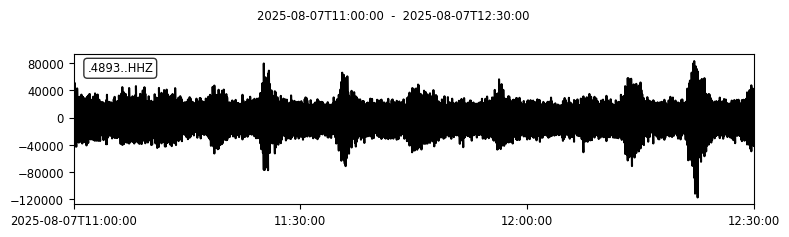

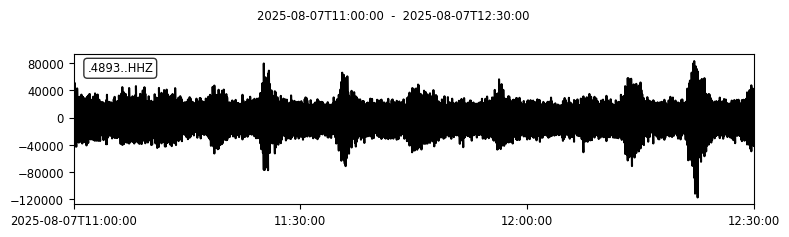

In [7]:
st_bb = obspy.read("/mnt/ICELAND_2024/GUNNUVHER/Seismic/Broadband/data/2025/202508/20250807/*z6*.gcf")
st_bb.merge(fill_value='interpolate')
st_bb.detrend(type='demean')
st_bb.trim(starttime=obspy.UTCDateTime("2025-08-07T11:00:00"), endtime=obspy.UTCDateTime("2025-08-07T12:30:00"))
st_bb_f = st_bb.copy()
st_bb_f.filter('bandpass', freqmin=1e-3, freqmax=0.25, corners=4)
st_bb_f.taper(.01)
st_bb.plot()

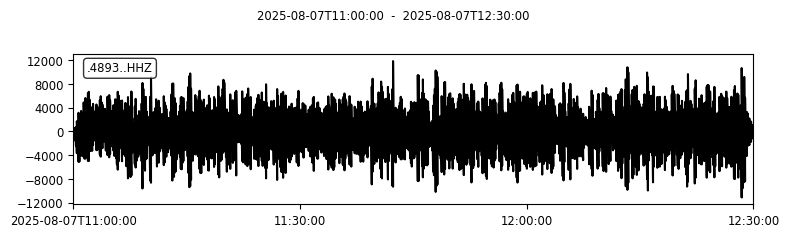

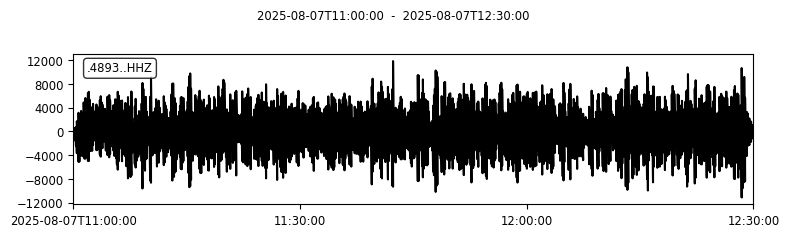

In [8]:
st_bb_f.plot()

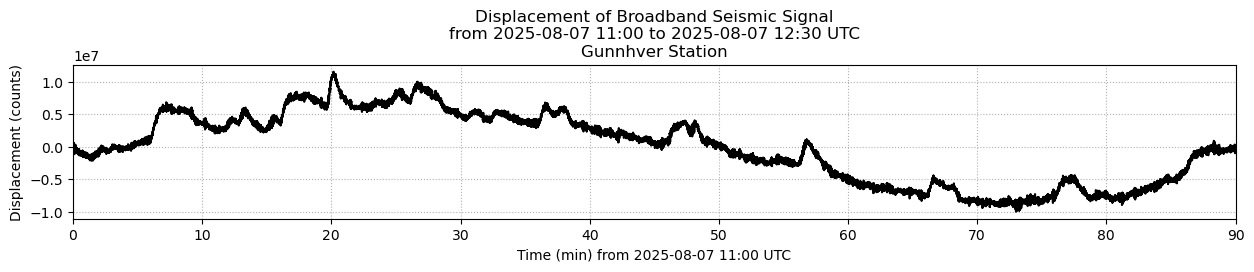

In [10]:
%matplotlib inline
fig, ax = plt.subplots(nrows=1, figsize=(15,2), sharex=True)
ax.plot(st_bb[0].times()[:-1]/60, (cumulative_trapezoid(detrend(st_bb[0].data))), color='k')
ax.grid(ls=':')
ax.set_title('Displacement of Broadband Seismic Signal\nfrom 2025-08-07 11:00 to 2025-08-07 12:30 UTC\nGunnhver Station')
#ax[0].plot(st_bb_f[0].times()[:-1], cumulative_trapezoid(st_bb_f[0].data), color='r')
#f,t, Sxx = spectrogram(cumulative_trapezoid(detrend(st_bb[0].data)), fs=st_bb[0].stats.sampling_rate, nperseg=10000, noverlap=9000, scaling='spectrum')
#im = ax[1].pcolormesh(t/60, f, 10*np.log10(Sxx**2), shading='gouraud', cmap='magma', norm=mcolors.Normalize(vmin=-150,vmax=250),)
#ax[1].set_yscale('log')
#ax[1].set_ylim(1e-2, .25)
ax.set_xlim(st_bb[0].times()[0]/60, st_bb[0].times()[-1]/60)
#ax[0].set_ylabel('Displacement (counts)')
#ax[1].set_ylabel('Frequency (Hz)')
#fig.colorbar(im, ax=ax[1], label='PSD (10*log10(counts$^2$/Hz))', orientation='horizontal', shrink=.2, pad=0.35)
ax.set_xlabel('Time (min) from 2025-08-07 11:00 UTC')
ax.set_ylabel('Displacement (counts)')
fig.savefig(plot_dir+'/displacement_bb_spectrogram_15min.png', bbox_inches='tight')
plt.show()